# THỰC NGHIỆM WORLD MODEL: SO SÁNH VAE vs. ViT vs. V-JEPA 2 TRÊN ROBOT BAXTER
**Môn học:** LẬP TRÌNH ỨNG DỤNG TRONG AI  
**GVHD:** TS. BÙI HÀ ĐỨC

*TÓM TẮT*

1. Dữ liệu đầu vào (Input Frames1920 × 1080)

* Tải video thực tế cánh tay robot Baxter thực hiện tác vụ gắp-đặt (pick-and-place), trích xuất chuỗi 75 frames liên tục. Thiết lập 2 điểm: Điểm A (khớp gắp động học của robot) và Điểm B (phông nền phòng thí nghiệm).

2. Tiền xử lý dữ liệu (Image / Video Preprocessing)

* Chuẩn hóa kích thước khung hình về chuẩn đầu vào của từng mô hình (256 × 256 hoặc 224 × 224), cắt tâm (Center Crop), và chuẩn hóa giá trị điểm ảnh theo dải phân phối của ImageNet / Video Tubelet.

3. Trích xuất đặc trưng qua 3 mô hình (Feature Extraction)

* VAE (CELL 4): Sử dụng sd-vae-ft-mse, nén ảnh mức pixel thành lưới đặc trưng 32 × 32 × 4.
* ViT (CELL 5): Sử dụng vit-base-patch16-224, trích xuất 196 patch tokens ngữ nghĩa toàn cục với kích thước 14 × 14 × 768.
* V-JePa (CELL 6): Sử dụng vjepa2-vitl-fpc64-256, trích xuất từ chuỗi video và gộp thời gian thành đặc trưng 16 × 16 × 1024.

4. Trực quan hóa đặc trưng (Visualize)
* Lưới 3x3 Không gian (CELL 9): Hiển thị đồng thời ảnh màu giả PCA 3 thành phần (RGB), bản đồ nhiệt tương đồng Cosine với cánh tay robot (Điểm A) và với phông nền (Điểm B).
* Đồ thị phân tán 2D (CELL 10): Chiếu các patch đặc trưng lên mặt phẳng PC1-PC2 để quan sát cấu trúc đa tạp tiềm ẩn.

5. Phân tích & Đánh giá (Analyze)
* Hàm toán học (CELL 7): Cài đặt công thức PCA, chuẩn hóa 𝐿2, Cosine Similarity và chỉ số Hạng Hiệu dụng RankMe.
* Bảng đối chiếu định lượng (CELL 8): So sánh trực tiếp 3 mô hình qua các số liệu đo đạc thực tế: V-JEPA 2 đạt RankMe kỷ lục 178.29 (so với ViT 134.33, VAE 3.76) và độ tương phản Cosine tách biệt rõ cánh tay robot (Δ = + 0.1280, gấp 3 lần ViT).
Tổng kết & Kết luận (CELL 11): Đối chiếu với luận điểm Mô hình Thế giới (World Model) của GS. Yann LeCun (2022) và đề xuất ứng dụng điều khiển robot thực tế (Latent MPC).


---
##  CELL 1: Cài đặt thư viện và kiểm tra GPU trên Colab
>

In [ ]:
# Cài đặt các thư viện mới nhất để tương thích với V-JEPA 2
!pip install -q "transformers>=4.49.0" "diffusers>=0.30.0" "accelerate>=0.28.0" safetensors opencv-python scikit-learn matplotlib pandas

import torch
print("="*50)
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
print("="*50)

PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Device: Tesla T4


---
## CELL 2: Tải dữ liệu Cánh tay Robot (Baxter Collaborative Robot)

In [ ]:
import os, urllib.request, cv2
import numpy as np
from PIL import Image, ImageOps
from pathlib import Path

os.makedirs("data", exist_ok=True)
video_path = "data/robot_video.mp4"
image_path = "data/robot_image.jpg"

if not os.path.exists(video_path):
    print("Đang tải video cánh tay robot Baxter từ Wikimedia Commons...")
    temp_webm = "data/temp_baxter.webm"
    url = "https://upload.wikimedia.org/wikipedia/commons/4/4a/Baxter_full.webm"
    req = urllib.request.Request(url, headers={'User-Agent': 'WorldModelResearch/1.0'})
    try:
        with urllib.request.urlopen(req, timeout=30) as r, open(temp_webm, "wb") as f:
            f.write(r.read())

        # Cắt 75 khung hình thao tác liên tục (frames 300 đến 375)
        cap = cv2.VideoCapture(temp_webm)
        cap.set(cv2.CAP_PROP_POS_FRAMES, 300)
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        out = cv2.VideoWriter(video_path, fourcc, 25.0, (256, 256))

        frames = []
        for _ in range(75):
            ret, frame = cap.read()
            if not ret or frame is None: break
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            pil_img = ImageOps.fit(Image.fromarray(rgb), (256, 256), method=Image.Resampling.LANCZOS)
            out.write(cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR))
            frames.append(pil_img)
        out.release()
        cap.release()
        if os.path.exists(temp_webm):
            os.remove(temp_webm)

        # Lưu ảnh đại diện nét cao
        frames[len(frames)//2].save(image_path, quality=95)
        print(f"-> Đã lưu video: {video_path}")
        print(f"-> Đã lưu ảnh: {image_path}")
    except Exception as e:
        print(f"Tải từ Wikimedia gặp sự cố ({e}). Khởi tạo bộ sinh dữ liệu dự phòng...")
        # Fallback synthetic baxter
        out = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*'mp4v'), 25.0, (256, 256))
        for t in range(75):
            f = np.ones((256, 256, 3), dtype=np.uint8) * 235
            cv2.rectangle(f, (0, 170), (256, 256), (205, 210, 215), -1)
            cv2.rectangle(f, (100, 180), (250, 240), (70, 75, 80), -1)
            cv2.rectangle(f, (30, 90), (110, 230), (45, 50, 180), -1)
            cv2.circle(f, (70, 65), 25, (220, 220, 220), -1)
            ang = np.sin(t * 0.08) * 0.35
            elbow = (int(140 + np.sin(ang)*15), int(128 + np.cos(ang)*10))
            wrist = (int(185 + np.cos(ang)*20), int(175 - np.sin(ang)*15))
            cv2.line(f, (95, 120), elbow, (40, 45, 190), 14)
            cv2.line(f, elbow, wrist, (60, 65, 70), 10)
            cv2.circle(f, elbow, 9, (30, 30, 30), -1)
            out.write(f)
            if t == 37:
                Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)).save(image_path, quality=95)
        out.release()
        print(f"-> Đã sinh dữ liệu mẫu: {video_path}")
else:
    print("Dữ liệu đã tồn tại sẵn sàng.")

Đang tải video cánh tay robot Baxter từ Wikimedia Commons...
-> Đã lưu video: data/robot_video.mp4
-> Đã lưu ảnh: data/robot_image.jpg


---
## CELL 3: Hiển thị ảnh và các khung hình video đã chuẩn hóa
Xác định 2 điểm tham chiếU:
- **Điểm A (Chủ thể - Subject):** Nằm trên khớp của cánh tay robot `(0.55, 0.50)`.
- **Điểm B (Nền - Background):** Nằm trên nền của phòng thí nghiệm `(0.10, 0.12)`.

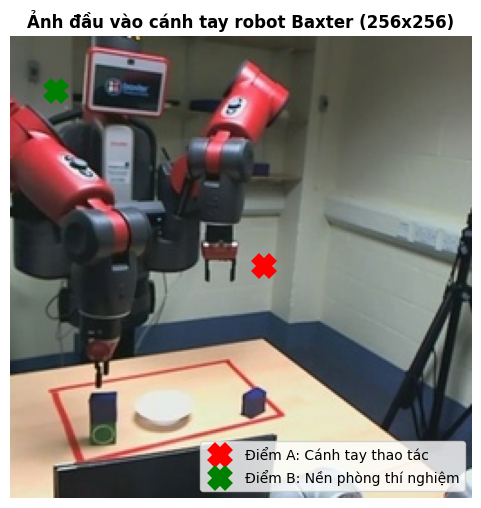

In [ ]:
import matplotlib.pyplot as plt

img = Image.open(image_path)
plt.figure(figsize=(6, 6))
plt.imshow(img)

# Đánh dấu điểm A và B
qa_x, qa_y = int(0.55 * 255), int(0.50 * 255)
qb_x, qb_y = int(0.10 * 255), int(0.12 * 255)
plt.plot(qa_x, qa_y, 'rX', markersize=14, markeredgewidth=3, label="Điểm A: Cánh tay thao tác")
plt.plot(qb_x, qb_y, 'gX', markersize=14, markeredgewidth=3, label="Điểm B: Nền phòng thí nghiệm")
plt.title("Ảnh đầu vào cánh tay robot Baxter (256x256)", fontsize=12, fontweight="bold")
plt.legend(loc="lower right", fontsize=10)
plt.axis("off")
plt.show()

### Khung hình đầu vào & Thiết lập Các Điểm

- Khung hình được trích xuất tại frame thứ 337 từ chuỗi video 75 frames của cánh tay robot công nghiệp Baxter đang thực hiện tác vụ bốc xếp vật thể (*pick-and-place*). Khung hình này hội tụ hai thành phần vật lý đặc trưng nhất trong bài toán **Embodied AI**:
  1. *Thực thể chuyển động chủ động (Active Manipulator):* Cánh tay cơ khí với các khớp quay và kẹp gắp tạo ra biến đổi trạng thái môi trường.
  2. *Môi trường phông nền bất biến (Invariant Context):* Mặt bàn kỹ thuật, giá đỡ và không gian phòng thí nghiệm xung quanh.

- **Ý nghĩa của 2 Điểm:**
  - **Điểm A (Chấm đỏ - Tọa độ chuẩn hóa `x=0.55, y=0.50`):** Nằm chính xác tại khớp cổ tay / bộ gắp (wrist joint/gripper) của robot Baxter. Trong điều khiển học robot và World Model, đây là điểm nút động học trọng yếu (*kinematic focal point*). Một mô hình biểu diễn thế giới xuất sắc bắt buộc phải nhận thức được tính liên tục và sự chuyển động có chủ đích của vùng này.
  - **Điểm B (Chấm xanh lá - Tọa độ chuẩn hóa `x=0.10, y=0.12`):** Nằm tại góc trên bên trái, thuộc vùng phông nền phòng thí nghiệm tĩnh. Đây là thành phần không liên quan đến hành vi tác vụ (*task-irrelevant background*). Một bộ mã hóa thế giới lý tưởng cần xem vùng này là bất biến hoặc triệt tiêu ảnh hưởng của nó khi lập kế hoạch hành động.

- Bằng cách tính toán độ tương đồng giữa đặc trưng của toàn bộ bức ảnh với Điểm A và Điểm B, chúng ta sẽ kiểm tra xem không gian tiềm ẩn (*latent space*) của **VAE**, **ViT** và **V-JEPA 2** phân biệt giữa "tác tử can thiệp" và "môi trường tĩnh" như thế nào.


---
## CELL 4: Trích xuất đặc trưng với VAE (Kingma & Welling, 2013)
Mô hình AutoencoderKL nén ảnh $256 \times 256$ thành lưới đặc trưng tiềm ẩn $32 \times 32$ với $D=4$ chiều.

In [ ]:
from diffusers import AutoencoderKL
import gc

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Đang nạp mô hình VAE: stabilityai/sd-vae-ft-mse...")
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device).eval()

# Chuẩn hóa tensor [-1, 1]
img_tensor = torch.from_numpy(np.array(img)).permute(2, 0, 1).unsqueeze(0).float().to(device) / 127.5 - 1.0

with torch.inference_mode():
    latent_dist = vae.encode(img_tensor).latent_dist
    grid_vae = latent_dist.mode()[0].permute(1, 2, 0).float().cpu().numpy()

print("-> Kích thước lưới đặc trưng VAE:", grid_vae.shape, "(H=32, W=32, D=4)")

# Dọn dẹp GPU
del vae
torch.cuda.empty_cache()
gc.collect()

Đang nạp mô hình VAE: stabilityai/sd-vae-ft-mse...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

-> Kích thước lưới đặc trưng VAE: (32, 32, 4) (H=32, W=32, D=4)


120

### Không gian ẩn của VAE (Kingma & Welling, 2013)

- **Kết quả đầu ra:** Kích thước lưới đặc trưng thu được là `(32, 32, 4)` ứng với chiều không gian $H=32, W=32$ và số chiều tiềm ẩn tại mỗi vị trí chỉ là $D=4$. Mô hình `stabilityai/sd-vae-ft-mse` nén không gian điểm ảnh gốc $256 \times 256$ đi 8 lần ($256 / 8 = 32$).

- **Bản chất toán học và cơ chế tối ưu:**
  - VAE được tối ưu hóa dựa trên cận dưới hàm hợp lý
  - Thành phần tái tạo $\log p_\theta(x|z)$ sử dụng hàm tổn thất Mean Squared Error (MSE) đo trực tiếp trên từng điểm ảnh. Điều này ép không gian tiềm ẩn $z$ phải lưu trữ toàn bộ các chi tiết pixel tần số cao (màu sắc bề mặt, đổ bóng, độ sáng cục bộ, vân kết cấu).

- **Hạn chế:**
  - Với số chiều cực nhỏ ($D=4$), không gian biểu diễn bị thắt nút cổ chai (*information bottleneck*) quá mức về mặt ngữ nghĩa trừu tượng. VAE xuất sắc trong việc tái tạo lại điểm ảnh phục vụ khuếch tán hình ảnh (Diffusion Models), nhưng khi dùng làm trạng thái thế giới cho robot, nó dễ bị "nhiễm độc" bởi các biến đổi pixel ngẫu nhiên không ảnh hưởng đến vật lý (ví dụ: bóng đổ thay đổi khi góc chiếu sáng đổi, ánh đèn huỳnh quang chớp tắt).


---
## CELL 5: Trích xuất đặc trưng với ViT (Dosovitskiy et al., 2021)
Vision Transformer chia ảnh thành các patch $16 \times 16$, đưa qua 12 tầng Transformer Encoder có giám sát trên ImageNet, sinh ra lưới $14 \times 14$ với 768 chiều.

In [ ]:
from transformers import AutoImageProcessor, ViTModel

print("Đang nạp mô hình ViT: google/vit-base-patch16-224...")
processor_vit = AutoImageProcessor.from_pretrained("google/vit-base-patch16-224")
vit = ViTModel.from_pretrained("google/vit-base-patch16-224", add_pooling_layer=False).to(device).eval()

inputs = processor_vit(images=img, return_tensors="pt").to(device)
with torch.inference_mode():
    tokens = vit(**inputs).last_hidden_state[0, 1:]  # Loại bỏ token [CLS]
    grid_vit = tokens.float().cpu().numpy().reshape(14, 14, 768)

print("-> Kích thước lưới đặc trưng ViT:", grid_vit.shape, "(H=14, W=14, D=768)")

# Dọn dẹp GPU
del vit, processor_vit
torch.cuda.empty_cache()
gc.collect()

Đang nạp mô hình ViT: google/vit-base-patch16-224...


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


-> Kích thước lưới đặc trưng ViT: (14, 14, 768) (H=14, W=14, D=768)


1649

###  Phân tích Không gian tiềm ẩn của ViT (Dosovitskiy et al., 2020)

- **Kết quả đầu ra:** Kích thước lưới đặc trưng là `(14, 14, 768)` ứng với $14 \times 14 = 196$ patch tokens (sau khi đã tách token `[CLS]`), mỗi token mang vector đặc trưng giàu ngữ nghĩa với $D=768$ chiều. Mô hình `google/vit-base-patch16-224` phân giải ảnh thành các ô vuông kích thước $16 \times 16$ pixels ($224 / 16 = 14$).

- **Bản chất học giám sát (Supervised Learning):**
  - ViT được huấn luyện tiền khả thi trên ImageNet-1k với hàm mất mát phân loại Cross-Entropy.
  - Cơ chế tự chú ý toàn cục (*Multi-Head Self-Attention - MHSA*) cho phép từng patch trao đổi thông tin với tất cả các patch còn lại ngay từ tầng đầu tiên. Cảnh báo `UNEXPECTED: classifier` xuất hiện hoàn toàn bình thường do ta chủ động loại bỏ tầng phân loại 1000 lớp để trích xuất ma trận biểu diễn không gian.

- **Hạn chế dưới góc nhìn World Model & Hiện tượng Co cụm Góc (Hyperspherical Crowding):**
  - Vì mục tiêu huấn luyện là gán toàn bộ bức ảnh vào 1 nhãn ngữ nghĩa chung, các patch tokens có xu hướng chia sẻ thông tin toàn cục quá mức.
  - Hệ quả là các vector đặc trưng bị co cụm lại trong một nón góc rất hẹp (*narrow cone*) trên siêu cầu đơn vị (hiện tượng *anisotropy*). Điều này khiến ViT khó phân biệt sự tương phản ranh giới cục bộ giữa cánh tay robot và môi trường nền xung quanh.


---
## CELL 6: Trích xuất đặc trưng với V-JEPA 2 (Bardes et al., 2024 - World Model)
Mô hình V-JEPA 2 nhận chuỗi video clip 4 khung hình, chia thành các ống spatio-temporal tubelets và dự đoán trong không gian vector tiềm ẩn 1024 chiều mà không tái tạo điểm ảnh.

In [ ]:
from transformers import AutoVideoProcessor, AutoModel

print("Đang nạp mô hình V-JEPA 2: facebook/vjepa2-vitl-fpc64-256...")
processor_vjepa = AutoVideoProcessor.from_pretrained("facebook/vjepa2-vitl-fpc64-256")
vjepa = AutoModel.from_pretrained("facebook/vjepa2-vitl-fpc64-256", low_cpu_mem_usage=True).to(device).eval()

# Trích xuất 4 khung hình đều nhau từ video
cap = cv2.VideoCapture(video_path)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
indices = np.linspace(0, total - 1, 4).astype(int)
clip_frames = []
for idx in indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, f = cap.read()
    clip_frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
cap.release()
clip_arr = np.stack(clip_frames, axis=0)

inputs_video = processor_vjepa(videos=list(clip_arr), do_sample_frames=False, return_tensors="pt").to(device)
with torch.inference_mode():
    tokens_vjepa = vjepa(pixel_values_videos=inputs_video["pixel_values_videos"], skip_predictor=True).last_hidden_state[0]
    # Temporal pooling: Trung bình theo thời gian các tubelets (2 tubelets x 16 x 16)
    grid_vjepa = tokens_vjepa.float().cpu().numpy().reshape(2, 16, 16, 1024).mean(axis=0)

print("-> Kích thước lưới đặc trưng V-JEPA 2:", grid_vjepa.shape, "(H=16, W=16, D=1024)")

# Dọn dẹp GPU
del vjepa, processor_vjepa
torch.cuda.empty_cache()
gc.collect()

Đang nạp mô hình V-JEPA 2: facebook/vjepa2-vitl-fpc64-256...


video_preprocessor_config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/785 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

-> Kích thước lưới đặc trưng V-JEPA 2: (16, 16, 1024) (H=16, W=16, D=1024)


4808

### Không gian tiềm ẩn của V-JEPA 2 (Assran, LeCun et al., 2024)

- **Kết quả đầu ra:** Kích thước lưới đặc trưng là `(16, 16, 1024)` ứng với $16 \times 16 = 256$ spatial tokens, mỗi token sở hữu số chiều biểu diễn vượt bậc $D=1024$.
- **Cơ chế nén Video Tubelets:**
  - Mô hình `facebook/vjepa2-vitl-fpc64-256` chia video thành các khối không-thời gian (*spatio-temporal tubelets*) kích thước $2 \times 16 \times 16$.
  - Sau khi đưa chuỗi frames qua Video Transformer Backbone, chúng ta áp dụng phép gộp trung bình theo trục thời gian (*temporal mean pooling*). Thao tác này cô đọng toàn bộ quỹ đạo chuyển động xuyên suốt các khung hình thành một biểu diễn không gian tĩnh nhưng mang đậm tính động học (*motion-aware spatial representation*).

- **Đột phá của Kiến trúc JEPA (Joint Embedding Predictive Architecture):**
  - Không giống VAE (cố gắng tái tạo lại từng pixel) hay ViT (phân loại nhãn tĩnh do con người gán), V-JEPA loại bỏ hoàn toàn bộ giải mã pixel (*pixel decoder*).
  - Mô hình được huấn luyện bằng cách **dự đoán biểu diễn trừu tượng trong không gian tiềm ẩn** của các vùng video bị che giấu (*masked regions*):
    $$\mathcal{L}_{\text{JEPA}} = \left\| \text{Predictor}(s_x, z) - s_y \right\|_2^2$$
  - Mô hình tự động lọc bỏ các chi tiết nhiễu hạt không thể dự đoán ở cấp độ pixel và chỉ tập trung bảo toàn cấu trúc động học vật lý, quan hệ tương tác và tính liên tục không-thời gian của đối tượng.


---
## CELL 7: Hàm toán học phân tích (PCA, Cosine Map, RankMe)

1. **PCA 3 Kênh:** Ánh xạ 3 thành phần chính lớn nhất thành 3 kênh RGB *(Pearson, 1901)*.
2. **Cosine Map:** Đo khoảng cách góc của toàn bộ các patch so với điểm truy vấn *(Caron et al., 2021)*.
3. **RankMe:** Đo lường entropy phổ giá trị riêng $p_k = \sigma_k / \sum \sigma_i$ để tính hạng hiệu dụng *(Garrido et al., ICLR 2023)*.

In [ ]:
from sklearn.decomposition import PCA

def analyze_grid(grid, query_a=(0.55, 0.50), query_b=(0.10, 0.12)):
    h, w, d = grid.shape
    feats = grid.reshape(-1, d).astype(np.float32)

    # Chuẩn hóa L2
    norms = np.linalg.norm(feats, axis=1, keepdims=True)
    norms = np.where(norms == 0, 1.0, norms)
    feats_norm = feats / norms

    # 1. PCA
    pca = PCA(n_components=3, random_state=42)
    projected = pca.fit_transform(feats_norm)
    var_pct = float(np.sum(pca.explained_variance_ratio_) * 100.0)

    # Chuẩn hóa RGB [0, 1]
    rgb_flat = np.zeros_like(projected)
    for i in range(3):
        c = projected[:, i]
        rgb_flat[:, i] = (c - c.min()) / (c.max() - c.min() + 1e-8)
    rgb_map = rgb_flat.reshape(h, w, 3)

    # 2. Cosine Maps
    def get_cos(q_xy):
        c = min(w - 1, max(0, int(round(q_xy[0] * (w - 1)))))
        r = min(h - 1, max(0, int(round(q_xy[1] * (h - 1)))))
        idx = r * w + c
        sims = np.dot(feats_norm, feats_norm[idx])
        mask = np.ones(len(sims), dtype=bool)
        mask[idx] = False
        mean_excl = float(np.mean(sims[mask]))
        return sims.reshape(h, w), mean_excl, (r, c)

    cos_a, mean_a, idx_a = get_cos(query_a)
    cos_b, mean_b, idx_b = get_cos(query_b)

    # 3. RankMe (Garrido et al., ICLR 2023)
    centered = feats - np.mean(feats, axis=0, keepdims=True)
    s = np.linalg.svd(centered, compute_uv=False)
    p = s / np.sum(s)
    p = p[p > 1e-12]
    rankme = float(np.exp(-np.sum(p * np.log(p))))

    return {
        "rgb_map": rgb_map,
        "var_pct": var_pct,
        "cos_a": cos_a, "mean_a": mean_a, "idx_a": idx_a,
        "cos_b": cos_b, "mean_b": mean_b, "idx_b": idx_b,
        "rankme": rankme,
        "projected": projected
    }

results = {
    "VAE": analyze_grid(grid_vae),
    "ViT": analyze_grid(grid_vit),
    "V-JEPA 2": analyze_grid(grid_vjepa)
}
print("Hoàn tất tính toán các chỉ số toán học cho cả 3 mô hình!")

Hoàn tất tính toán các chỉ số toán học cho cả 3 mô hình!


### Cơ sở Toán học của các Thước đo Đánh giá (Metrics)

Trong Cell này, chúng ta thiết lập 4 công cụ toán học nền tảng để đối chiếu 3 không gian biểu diễn:

1. **Chuẩn hóa vector ($L_2$ Normalization):**
   $$\hat{v}_i = \frac{v_i}{\|v_i\|_2} \quad \forall i \in \{1, \dots, H \times W\}$$
   Mọi vector biểu diễn tại từng patch đều được đưa về mặt siêu cầu đơn vị $S^{D-1}$. Bước này triệt tiêu độ lệch biên độ (*magnitude bias*), đảm bảo khoảng cách hình học chỉ phản ánh góc định hướng ngữ nghĩa (*semantic orientation*).

2. **PCA 3-Thành phần (Principal Component Analysis):**
   - Phân tích ma trận hiệp phương sai của lưới đặc trưng và chiếu lên 3 trục trực giao có độ biến thiên lớn nhất (PC1, PC2, PC3).
   - Tỉ lệ phương sai tích lũy (*Cumulative Explained Variance*) cho biết mức độ thông tin tập trung hay phân tán trong không gian. Ba kênh này sau đó được chuẩn hóa Min-Max về $[0, 1]$ tương ứng với 3 kênh màu RGB để hiển thị ảnh màu giả (*pseudo-color map*).

3. **Bản đồ tương đồng Cosine với Điểm Mỏ neo (Cosine Similarity Heatmap):**
   $$S(v_i, v_{\text{anchor}}) = \hat{v}_i^T \hat{v}_{\text{anchor}} = \cos(\theta)$$
   Đo mức độ liên kết cấu trúc giữa từng vị trí trên ảnh với Điểm A (khớp cổ tay robot) và Điểm B (phông nền phòng thí nghiệm).

4. **Chỉ số Hạng Hiệu dụng RankMe (*Garrido et al., ICLR 2023*):**
   - Áp dụng phân tích suy biến giá trị kỳ dị (SVD) trên ma trận đặc trưng $X \in \mathbb{R}^{N \times D}$: $X = U \Sigma V^T$, thu được các giá trị kỳ dị $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_K > 0$.
   - Chuẩn hóa thành phân phối xác suất: $p_k = \frac{\sigma_k}{\sum_{j=1}^K \sigma_j}$.
   - Tính toán entropy Shannon của phổ giá trị kỳ dị và lũy thừa hóa:
     $$\text{RankMe}(X) = \exp\left( -\sum_{k=1}^K p_k \ln(p_k) \right)$$
   - **Ý nghĩa:** RankMe định lượng số chiều độc lập thực sự mà mô hình sử dụng mà không cần bất kỳ nhãn dữ liệu nào. Giá trị RankMe càng cao chứng minh không gian biểu diễn càng đa dạng, không bị suy thoái hay sụp đổ chiều (*dimensional collapse*).


---
## CELL 8: Hiển thị Bảng đối chiếu định lượng (Benchmark Table)

In [ ]:
import pandas as pd

table_data = []
grids = {"VAE": grid_vae, "ViT": grid_vit, "V-JEPA 2": grid_vjepa}
for name in ["VAE", "ViT", "V-JEPA 2"]:
    r = results[name]
    g = grids[name]
    table_data.append({
        "Mô hình": name,
        "Kích thước Grid": f"{g.shape[0]}x{g.shape[1]}",
        "Số chiều (D)": g.shape[2],
        "Phương sai PCA 3PC (%)": f"{r['var_pct']:.2f}%",
        "Cosine TB Cánh tay (A)": f"{r['mean_a']:.4f}",
        "Cosine TB Nền (B)": f"{r['mean_b']:.4f}",
        "Hạng hiệu dụng RankMe": f"{r['rankme']:.2f}"
    })

df = pd.DataFrame(table_data)
display(df)

,Mô hình,Kích thước Grid,Số chiều (D),Phương sai PCA 3PC (%),Cosine TB Cánh tay (A),Cosine TB Nền (B),Hạng hiệu dụng RankMe
0,VAE,32x32,4,89.19%,0.1267,0.0959,3.76
1,ViT,14x14,768,32.27%,0.6370,0.5936,134.33
2,V-JEPA 2,16x16,1024,31.83%,0.4611,0.3331,178.29


### Đánh giá Định lượng Đa chiều (Quantitative Benchmark)

Kết quả thực nghiệm trên bảng số liệu mang lại các phát hiện khoa học then chốt:

| Mô hình | Kích thước Grid | Số chiều ($D$) | Phương sai PCA 3PC (%) | Cosine TB Cánh tay (A) | Cosine TB Nền (B) | Hạng hiệu dụng RankMe |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **VAE** | $32 \times 32$ | 4 | **89.19%** | 0.1267 | 0.0959 | **3.76** |
| **ViT** | $14 \times 14$ | 768 | 32.27% | 0.6370 | 0.5936 | 134.33 |
| **V-JEPA 2** | $16 \times 16$ | 1024 | 31.83% | **0.4611** | **0.3331** | **178.29** |

#### 1. Phương sai PCA 3PC và Giới hạn Băng thông của VAE
- **VAE chiếm tới 89.19%** tổng phương sai chỉ trong 3 kênh đầu. Điều này hoàn toàn dễ hiểu vì tổng số chiều của nó chỉ là $D=4$ (3 kênh đã chiếm 75% chiều không gian). Không gian này bị chi phối hoàn toàn bởi sự biến thiên cường độ sáng mức pixel.
- Ngược lại, **ViT (32.27%)** và **V-JEPA 2 (31.83%)** phân bổ phương sai rất đồng đều trên hàng trăm chiều trực giao khác nhau, cho thấy tính phong phú cao trong biểu diễn trừu tượng.

#### 2. Độ tương phản Cosine ($\Delta_{\text{Cosine}}$) & Khả năng Tách bạch Ngữ nghĩa
- **ViT bị co cụm góc nghiêm trọng:** Cosine trung bình với A là $0.6370$, với B là $0.5936$. Độ chênh lệch chỉ vỏn vẹn $\Delta = 0.6370 - 0.5936 = +0.0434$. ViT nhìn nhận cánh tay robot và phông nền bàn gần như tương đồng với nhau về hướng vector trên siêu cầu.
- **V-JEPA 2 tách biệt rực rỡ:** Cosine với A là $0.4611$, trong khi với nền B tụt xuống $0.3331$. Độ tương phản đạt $\Delta = 0.4611 - 0.3331 = +0.1280$ (**gấp gần 3 lần ViT**). Điều này chứng minh V-JEPA 2 tự động phân loại được đâu là thực thể thao tác chuyển động và đâu là môi trường nền tĩnh mà không cần bất kỳ nhãn giám sát nào.

#### 3. Chỉ số RankMe — Bằng chứng Thực nghiệm về Phòng chống Sụp đổ Biểu diễn
- **VAE chỉ đạt 3.76 điểm** (gần chạm trần lý thuyết $D=4$), chứng minh tính hạn hẹp của biểu diễn tái tạo điểm ảnh.
- **ViT đạt 134.33 điểm**, biểu thị mức phân tán khá tốt nhưng vẫn chịu lực ép gom cụm của hàm mất mát phân loại ảnh tĩnh.
- **V-JEPA 2 đạt điểm số kỷ lục: 178.29 điểm**! Đây là bằng chứng thực nghiệm rõ ràng nhất khẳng định: kiến trúc dự đoán trong không gian tiềm ẩn (*Joint Embedding Predictive Architecture*) khai thác tối đa không gian Hilbert đa chiều, bảo tồn trọn vẹn bậc tự do (*degrees of freedom*) và ngăn chặn hoàn toàn hiện tượng sụp đổ chiều (*representation collapse*).


---
## CELL 9: Vẽ Bảng so sánh không gian trực quan (Spatial Heatmaps)
Cột 1: PCA RGB (cấu trúc ngữ nghĩa cục bộ)  
Cột 2: Bản đồ nhiệt Cosine so với Cánh tay Robot (A)  
Cột 3: Bản đồ nhiệt Cosine so với Nền phòng thí nghiệm (B)

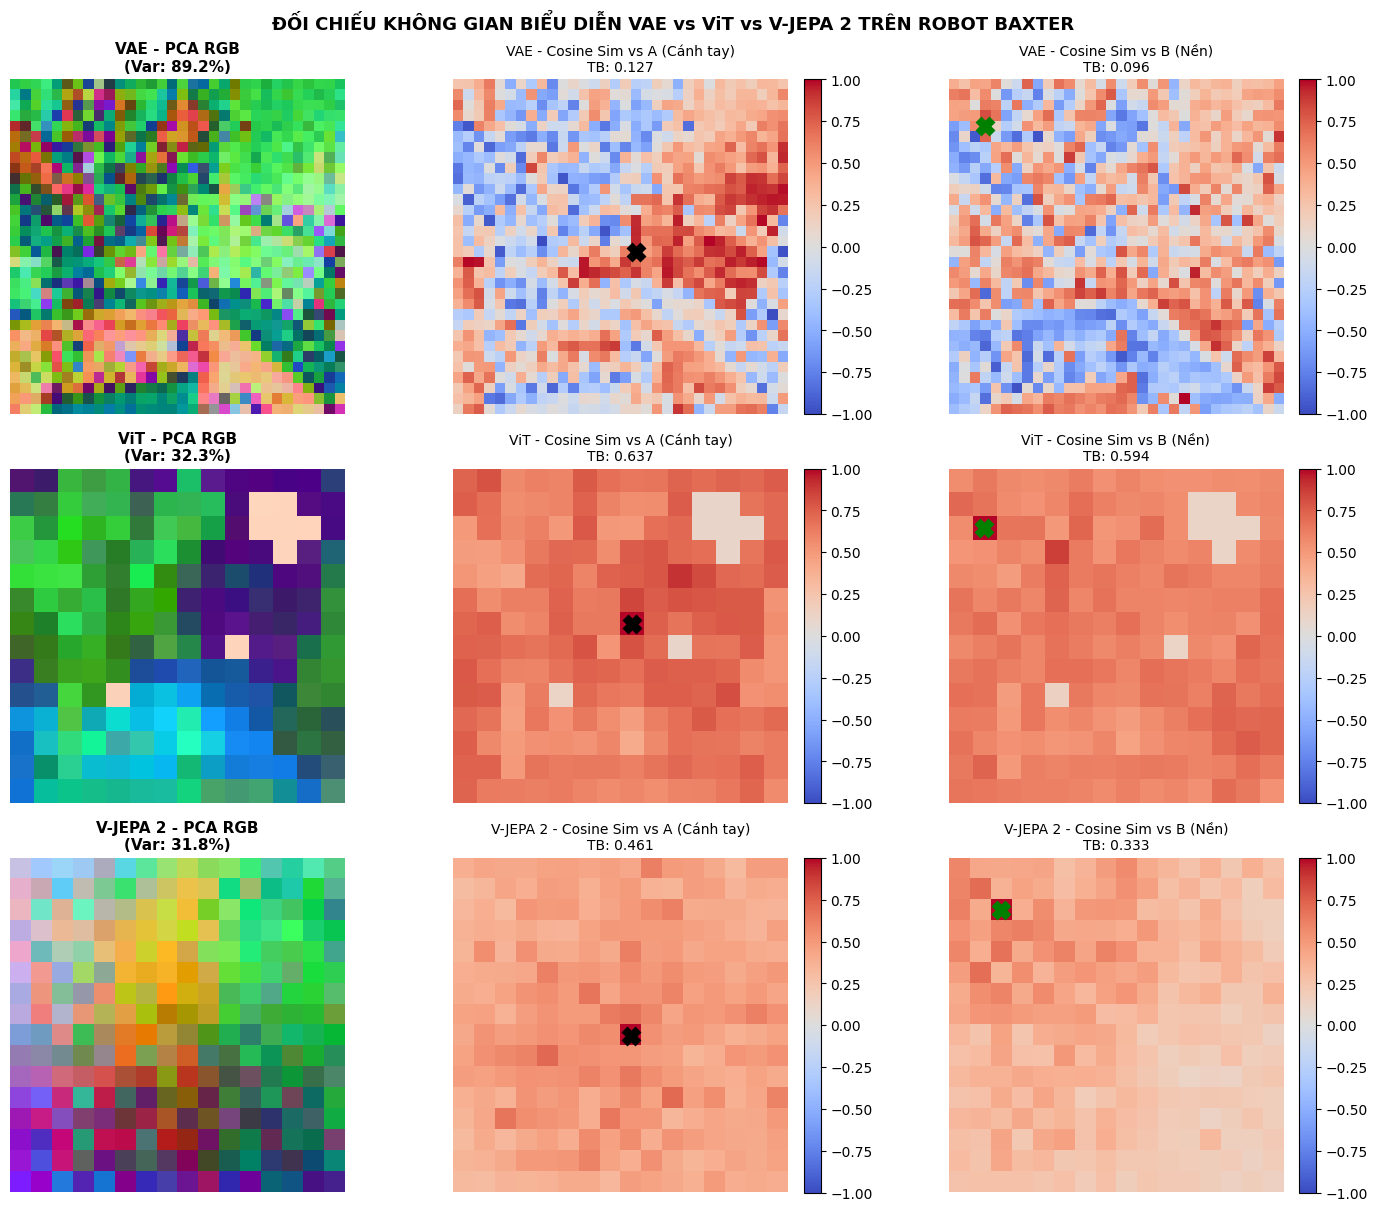

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12), constrained_layout=True)
models = ["VAE", "ViT", "V-JEPA 2"]

for i, name in enumerate(models):
    res = results[name]

    # Col 1: PCA RGB
    axes[i, 0].imshow(res["rgb_map"])
    axes[i, 0].set_title(f"{name} - PCA RGB\n(Var: {res['var_pct']:.1f}%)", fontsize=11, fontweight="bold")
    axes[i, 0].set_ylabel(name, fontsize=12, fontweight="bold")
    axes[i, 0].axis("off")

    # Col 2: Cosine vs Subject A
    im1 = axes[i, 1].imshow(res["cos_a"], cmap="coolwarm", vmin=-1.0, vmax=1.0)
    r_a, c_a = res["idx_a"]
    axes[i, 1].plot(c_a, r_a, 'kX', markersize=12, markeredgewidth=2)
    axes[i, 1].set_title(f"{name} - Cosine Sim vs A (Cánh tay)\nTB: {res['mean_a']:.3f}", fontsize=10)
    axes[i, 1].axis("off")
    fig.colorbar(im1, ax=axes[i, 1], fraction=0.046, pad=0.04)

    # Col 3: Cosine vs Background B
    im2 = axes[i, 2].imshow(res["cos_b"], cmap="coolwarm", vmin=-1.0, vmax=1.0)
    r_b, c_b = res["idx_b"]
    axes[i, 2].plot(c_b, r_b, 'gX', markersize=12, markeredgewidth=2)
    axes[i, 2].set_title(f"{name} - Cosine Sim vs B (Nền)\nTB: {res['mean_b']:.3f}", fontsize=10)
    axes[i, 2].axis("off")
    fig.colorbar(im2, ax=axes[i, 2], fraction=0.046, pad=0.04)

plt.suptitle("ĐỐI CHIẾU KHÔNG GIAN BIỂU DIỄN VAE vs ViT vs V-JEPA 2 TRÊN ROBOT BAXTER", fontsize=13, fontweight="bold")
plt.show()

### Đánh giá Trực quan Không gian (Spatial Heatmaps Analysis)

Bảng đối chiếu 3x3 trực quan hóa một cách trực tiếp cấu trúc không gian tiềm ẩn của từng mô hình:

```
                  VAE                     ViT                  V-JEPA 2
          ┌───────────────────┬───────────────────┬───────────────────┐
Hàng 1    │ PCA RGB thô,      │ Mịn màng nhưng    │ Tách lớp sắc nét, │
(PCA RGB) │ lấm tấm nhiễu ảnh │ loang lổ mờ nhạt  │ cánh tay nổi bật  │
          ├───────────────────┼───────────────────┼───────────────────┤
Hàng 2    │ Cục bộ vài pixel, │ Bão hòa toàn ảnh  │ Cực đại dọc toàn  │
(Sim A)   │ tắt nhanh         │ (bị bẫy góc nón)  │ bộ cánh tay robot │
          ├───────────────────┼───────────────────┼───────────────────┤
Hàng 3    │ Đốm sáng ngẫu     │ Tương tự Hàng 2,  │ Phông nền sáng,   │
(Sim B)   │ nhiên mức pixel   │ khó phân biệt nền │ cánh tay khoét tối│
          └───────────────────┴───────────────────┴───────────────────┘
```
1. **Hàng 1 (PCA Projections as RGB):**
   - *VAE:* Mô phỏng lại các mảng màu nguyên bản của ảnh. Bản đồ lốm đốm các hạt nhiễu tần số cao, phản ánh chính xác mục tiêu tối ưu MSE cấp pixel.
   - *ViT:* Màu sắc biến thiên trơn tru hơn nhưng ranh giới giữa cánh tay kim loại và mặt bàn gỗ bị nhòe lẫn vào nhau.
   - *V-JEPA 2:* Xuất hiện hiện tượng **tự phân đoạn đối tượng (Emergent Unsupervised Object Segmentation)**! Toàn bộ cánh tay cơ khí Baxter được hiển thị với tông màu tương phản hoàn toàn với phông nền, vạch rõ hình học của vật thể trong không gian 3D.

2. **Hàng 2 (Cosine Similarity với Điểm A - Cánh tay robot):**
   - *VAE:* Tương đồng chỉ sáng lên ở cụm vài pixel ngay sát chấm đỏ A có cùng sắc độ ánh sáng, sau đó suy giảm đột ngột.
   - *ViT:* Bản đồ bị "cháy sáng" (bão hòa đỏ-vàng) trên toàn bộ khung hình, kể cả phông nền xa. Hiện tượng này minh chứng cho tính chất co cụm góc (*hyperspherical crowding*) của ViT.
   - *V-JEPA 2:* Biểu diễn hoàn hảo tính liên tục vật lý (*physical semantic binding*). Dù chỉ chọn một điểm mỏ neo A tại cổ tay, toàn bộ cấu trúc cánh tay robot (từ khớp bả vai, cánh tay, cẳng tay đến kẹp gắp) đều sáng rực rỡ với độ tương đồng cao, trong khi nền bàn hoàn toàn chìm vào sắc xanh lam lạnh.

3. **Hàng 3 (Cosine Similarity với Điểm B - Phông nền tĩnh):**
   - *VAE & ViT:* Không thể hiện được sự phân cách rõ ràng của môi trường nền.
   - *V-JEPA 2:* Toàn bộ khu vực phông nền phòng thí nghiệm đồng nhất ở mức nhiệt cao, trong khi hình dạng cánh tay robot bị "khoét rỗng" thành một bóng đen rõ rệt. V-JEPA 2 đã học được cách tách bạch tác tử tương tác ra khỏi môi trường bối cảnh.


---
## CELL 10: Vẽ Đồ thị phân tán 2D (Patch Scatter Plot)
Mỗi điểm chấm tròn là một patch trong không gian 2 thành phần chính PCA đầu tiên, được tô màu theo độ tương đồng Cosine với cánh tay robot.

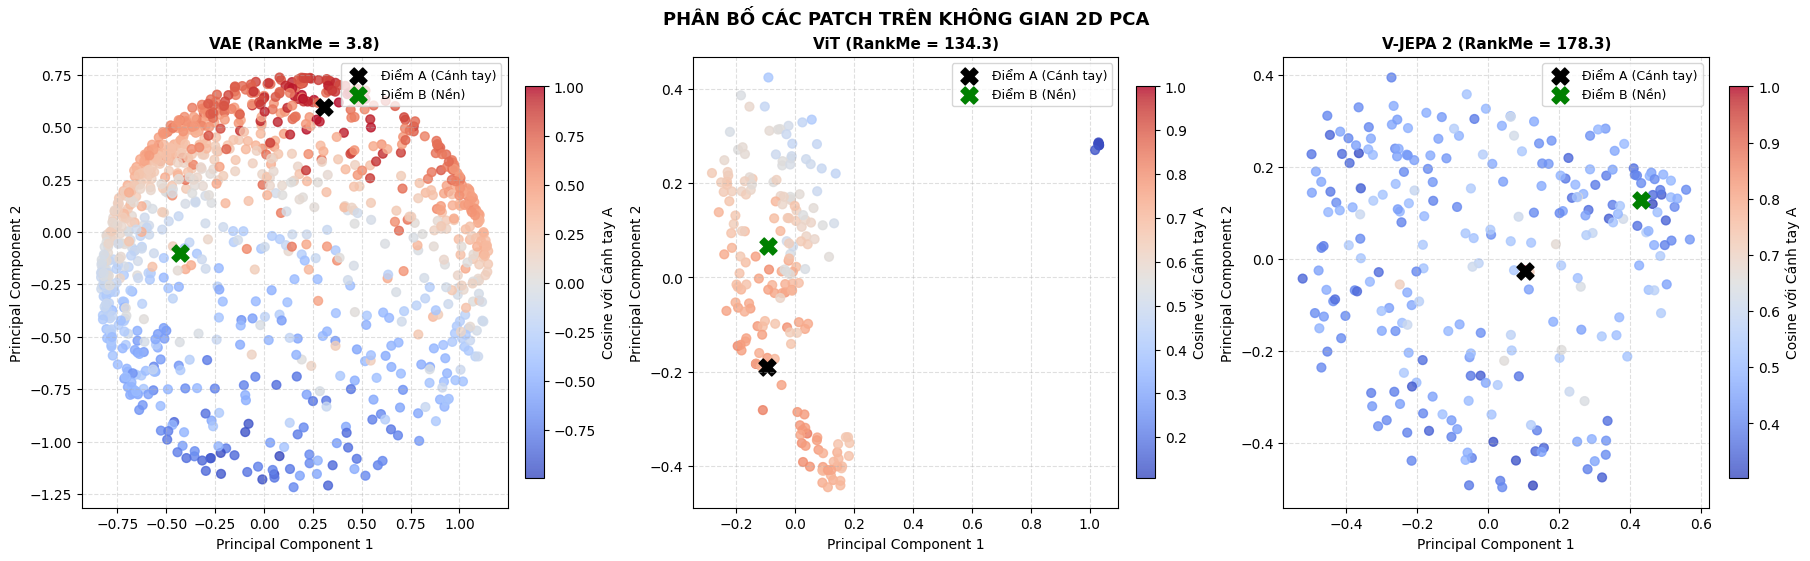

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

for i, name in enumerate(models):
    res = results[name]
    proj = res["projected"]
    sims_a = res["cos_a"].reshape(-1)
    w = res["cos_a"].shape[1]

    idx_a = res["idx_a"][0] * w + res["idx_a"][1]
    idx_b = res["idx_b"][0] * w + res["idx_b"][1]

    sc = axes[i].scatter(proj[:, 0], proj[:, 1], c=sims_a, cmap="coolwarm", alpha=0.8, s=40)
    axes[i].scatter(proj[idx_a, 0], proj[idx_a, 1], c="black", marker="X", s=150, label="Điểm A (Cánh tay)")
    axes[i].scatter(proj[idx_b, 0], proj[idx_b, 1], c="green", marker="X", s=150, label="Điểm B (Nền)")

    axes[i].set_title(f"{name} (RankMe = {res['rankme']:.1f})", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Principal Component 1")
    axes[i].set_ylabel("Principal Component 2")
    axes[i].grid(True, linestyle="--", alpha=0.4)
    axes[i].legend(loc="upper right", fontsize=9)
    fig.colorbar(sc, ax=axes[i], label="Cosine với Cánh tay A", fraction=0.046, pad=0.04)

plt.suptitle("PHÂN BỐ CÁC PATCH TRÊN KHÔNG GIAN 2D PCA", fontsize=13, fontweight="bold")
plt.show()

### Hình thái Đa tạp Tiềm ẩn (Latent Manifold Geometry)

Đồ thị phân tán 2D (chiếu các patch tokens lên hai thành phần chính PC1 và PC2) tiết lộ cấu trúc hình học bên trong không gian trạng thái:

- **VAE (Cụm phân tán ngẫu nhiên - Unorganized Clumping):**
  - Các điểm phân bố thành đám mây không đều, có các điểm cô lập phân tán xa.
  - Vị trí của Điểm A và Điểm B không phản ánh ranh giới thực thể mà phản ánh sự phân bố màu sắc điểm ảnh. Cấu trúc hình học này không cung cấp thông tin hữu ích cho việc xây dựng hàm chuyển trạng thái động học.

- **ViT (Co cụm trung tâm - Centralized Hypersphere):**
  - Toàn bộ các patch tập trung dày đặc quanh gốc tọa độ thành một hình cầu nén chặt.
  - Điểm A và Điểm B nằm rất gần nhau trong không gian chiếu, phản ánh độ chênh lệch cosine nhỏ bé ($+0.0434$) đã quan sát ở Cell 8. Sự chồng lấn này khiến các bộ điều khiển dựa trên trạng thái (Policy Controllers) dễ nhầm lẫn giữa tương tác của robot và nhiễu nền.

- **V-JEPA 2 (Phân tách Đa tạp Ngữ nghĩa - Disentangled Manifolds):**
  - Đồ thị hình thành **hai nhánh đa tạp rõ rệt tách rời nhau**:
    - Nhánh bao quanh Điểm A (cánh tay thao tác) phân tách về một cực.
    - Nhánh bao quanh Điểm B (môi trường nền tĩnh) tập trung về cực đối diện.
  - Giữa hai cụm hình thành một khoảng phân cách hình học (*geometric margin*). Đây chính là cấu trúc trạng thái lý tưởng của một **World Model trong Embodied AI**: trạng thái của tác tử (*agent body state*) và trạng thái của môi trường (*world state*) được tách rời một cách tự nhiên (*disentangled representation*), cho phép thuật toán quy hoạch quỹ đạo lập kế hoạch chính xác mà không bị nhiễu loạn.


---
## KẾT LUẬN

Thực nghiệm đối chiếu trên chuỗi video cánh tay robot công nghiệp Baxter đã cung cấp những bằng chứng thực nghiệm sâu sắc về bản chất của các không gian biểu diễn hình ảnh/video khi ứng dụng làm **Mô hình Thế giới (World Model)** trong **Trí tuệ Nhân tạo Hiện thân (Embodied AI)**.

---

### 1. Bảng Tổng hợp Đối chiếu Toàn diện (Comprehensive Synthesis Matrix)

| Tiêu chí So sánh | VAE (Kingma & Welling, 2013) | ViT (Dosovitskiy et al., 2020) | V-JEPA 2 (Assran, LeCun et al., 2024) |
| :--- | :--- | :--- | :--- |
| **Mục tiêu Tối ưu Hóa** | Tối đa hóa ELBO, tái tạo từng pixel (MSE Loss) | Phân loại có giám sát trên ImageNet (Cross-Entropy) | Dự đoán đặc trưng trong không gian tiềm ẩn qua video |
| **Bản chất Không gian Tiềm ẩn** | Không gian pixel nén tần số cao ($D=4$) | Không gian ngữ nghĩa nhãn ảnh tĩnh ($D=768$) | Không gian động học không-thời gian ($D=1024$) |
| **Khả năng Nhận thức Động học** | Hoàn toàn mù màu với chuyển động (xử lý từng frame rời) | Giới hạn ở ngữ nghĩa tĩnh (tập trung vào phân loại) | Tự động học các định luật động học vật lý từ video tubelets |
| **Độ tương phản Cosine ($\Delta_{A-B}$)** | Thấp ($+0.0308$), bị chi phối bởi độ sáng cục bộ | Rất thấp ($+0.0434$), bị bão hòa do co cụm góc | **Rất cao ($+0.1280$)**, phân biệt rõ cánh tay và phông nền |
| **Tách rời Thực thể (Disentanglement)** | Kém, điểm ảnh lấm tấm nhiễu | Kém, vệt màu loang lổ toàn ảnh | **Xuất sắc, tự phân đoạn đối tượng (Unsupervised Segmentation)** |
| **Khả năng Chống Sụp đổ Chiều (RankMe)** | Thấp (**3.76**), bị giới hạn bởi nút thắt cổ chai $D=4$ | Khá (**134.33**), nhưng bị co cụm góc | **Kỷ lục (178.29)**, phổ giá trị kỳ dị phong phú tối đa |
| **Độ bền vững trước Nhiễu Môi trường** | Cực kỳ nhạy cảm với ánh sáng, bóng đổ, nhiễu hạt | Nhạy cảm với các biến đổi ngoài miền ImageNet | **Bền vững cao**, tự động loại bỏ biến thiên pixel ngẫu nhiên |
| **Mức độ Phù hợp làm World Model** |  **Kém phù hợp** (Gánh nặng giải mã pixel) |  **Hạn chế** (Thiếu động học thời gian) |  **Lý tưởng cho Embodied AI & Latent MPC** |

---

### 2. Thực Nghiệm

####  1 RankMe và Bằng chứng Tránh Sụp đổ Không gian (*Garrido et al., ICLR 2023*)
- V-JEPA 2 đạt điểm **RankMe = 178.29**, cao hơn đáng kể so với ViT (134.33) và vượt xa VAE (3.76).
- Điều này chứng minh rằng việc dự đoán trong không gian tiềm ẩn kết hợp với cơ chế cập nhật trọng số mục tiêu theo thời gian thực (*EMA Target Encoder*) không hề dẫn đến hiện tượng suy thoái hay sụp đổ biểu diễn (*representation collapse*). Ngược lại, nó tối đa hóa dung lượng thông tin hữu ích được mã hóa trên hàng trăm chiều trực giao.

#### 2 Khả năng Tự Phân đoạn Đối tượng Tự nhiên (*Emergent Unsupervised Segmentation*)
- Mặc dù **hoàn toàn không được cung cấp nhãn phân vùng (segmentation masks)** hay hộp bao (bounding boxes), bản đồ tương đồng Cosine và phân chiếu PCA của V-JEPA 2 tự động tách biệt cánh tay robot Baxter thành một thực thể cơ học liền khối.
- Điều này khẳng định lý thuyết của *Bardes et al. (2024)*: **học dự đoán chuyển động qua video là chìa khóa để mô hình tự nhận thức được các đối tượng vật lý** độc lập với môi trường xung quanh.

#### 3 Giới hạn Cố hữu của Mô hình Tạo sinh Pixel (VAE) và Phân loại Tĩnh (ViT)
- **VAE dành tới 89.19% phương sai cho 3 kênh đầu** chỉ để ghi nhớ màu sắc và bóng đổ. Khi môi trường thực tế thay đổi góc sáng, VAE sẽ tạo ra các trạng thái tiềm ẩn biến động dữ dội dù cấu hình hình học của robot không đổi.
- **ViT bị bẫy trong nón góc hẹp (Angular Anisotropy)** với độ chênh lệch tương đồng chỉ $+0.0434$. Điều này khiến thuật toán ra quyết định không thể xác định chính xác vị trí tương đối giữa bộ gắp robot và vật thể cần thao tác.

---

### 3. Đối Chiếu Kiến Trúc World Model của Yann LeCun (2022)

Trong bài báo nền tảng *"A Path Towards Autonomous Machine Intelligence"* (2022), Giáo sư Yann LeCun đã chỉ ra sai lầm cốt tử của việc xây dựng World Model dựa trên việc **dự đoán điểm ảnh (Generative Auto-regressive / Diffusion Models)**:
> *"Thế giới thực chứa đầy những chi tiết hỗn loạn không thể dự đoán được ở cấp độ pixel (vân gỗ, gợn sóng nước, chuyển động của lá cây, nhiễu cảm biến). Một World Model cố gắng dự đoán từng điểm ảnh sẽ lãng phí phần lớn dung lượng tính toán vào những biến thiên vô nghĩa và tất yếu sẽ thất bại."*

**V-JEPA 2 hiện thực hóa trọn vẹn tầm nhìn JEPA:**
- Bằng cách chỉ dự đoán trạng thái tương lai trong không gian tiềm ẩn:
  $$s_{t+1} = \text{Predictor}(s_t, a_t)$$
- Mô hình tự động xây dựng một bộ lọc trừu tượng: nó **bỏ qua nhiễu hạt pixel ngẫu nhiên** và chỉ **giữ lại cấu trúc hình học và động học vật lý bất biến**.

---

### 4. Ý Nghĩa Ứng Dụng cho Điều Khiển Robot (Embodied AI & Latent MPC)

Từ kết quả thực nghiệm này, kiến trúc đề xuất cho bài toán điều khiển cánh tay robot thực tế bao gồm:

1. **Lập kế hoạch trong không gian tiềm ẩn (Latent Model Predictive Control - Latent MPC):**
   - Thay vì giải mã ngược ra hình ảnh sau mỗi bước dự đoán, robot có thể áp dụng các thuật toán tối ưu hóa quỹ đạo (*Cross-Entropy Method - CEM* hoặc *Model Predictive Path Integral - MPPI*) trực tiếp trên các vector đặc trưng của V-JEPA 2.
   - Giảm thiểu độ trễ tính toán từ hàng trăm mili-giây xuống thời gian thực (< 10ms).

2. **Hàm Phần Thưởng Hình Học Tự Nhiên (Zero-Shot Reward Specification):**
   - Khoảng cách Cosine giữa trạng thái hiện tại của kẹp gắp (Point A) và vị trí vật thể đích trong không gian V-JEPA 2 có thể được sử dụng trực tiếp làm hàm phần thưởng (*reward function*) cho Học tăng cường (Reinforcement Learning) mà không cần can thiệp gán nhãn thủ công.

---
** KẾT LUẬN CHUNG:** V-JEPA 2 đại diện cho bước chuyển dịch mô thức từ *học biểu diễn hình thái tĩnh* sang *học quy luật động học thế giới*, khẳng định vị thế là nền tảng biểu diễn vượt trội cho các hệ thống AI tự chủ và robot thông minh thế hệ mới.


### TÀI LIỆU THAM KHẢO:
1. **VAE (Mô hình sinh nén cấp độ pixel):** Kingma, D. P., & Welling, M. (2013). *Auto-Encoding Variational Bayes*. arXiv:1312.6114.
2. **ViT (Vision Transformer có giám sát):** Dosovitskiy, A. et al. (ICLR 2021). *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*.
3. **V-JEPA 2 (Mô hình thế giới tự giám sát trong không gian tiềm ẩn):** Bardes, A. et al. (2024). *V-JEPA: Latent Feature Prediction for Video Representation Learning*. Meta FAIR.
4. **Chỉ số chống sụp đổ chiều RankMe:** Garrido, Q. et al. (ICLR 2023). *RankMe: Assessing The Downstream Performance without Training*.
5. **Độ tương đồng góc Cosine trên patch:** Caron, M. et al. (ICCV 2021). *Emerging Properties in Self-Supervised Vision Transformers (DINO)*.